# Stage 2: NSGA-II (Table 5 settings) on BK15 / BK50 — results vs. the paper

Read-only viewer for `results/stage2-nsga2/`. To refresh, rerun:

```bash
uv run python experiments/stage2-nsga2.py
```

Setup (see `config` below and `docs/PROGRESS.md` section 5):
population 50, SBX rate 1, polynomial mutation 1/NG (distribution index 20 for both),
binary tournament; iteration = generation, snapshots at 50/100/200/300 (= 2,500 … 15,000 evaluations);
seeds 1–10. Seed 1 corresponds to the paper's protocol (one run per iteration size, R1); seeds 1–10 are R2.
OIDT objective = union of busy intervals per compartment (A1); the paper's M2 value is stored as `oidt_m2`.

Paper references (PDF `paper/s41598-022-26866-9.pdf`) come from `bakery.paper_ref`:
Table 4 (p.12) and text are exact; Fig. 7a (p.9), Fig. 10a (p.11), Fig. 11 (p.12) and Fig. 12 (p.13) values are figure readings.

**Caveat.** The paper's PF* pools five algorithms (one run each × 4 iteration sizes). Here PF* is *provisional*:
the nondominated union of all NSGA-II fronts (10 seeds × 4 snapshots). PDS / MSF / DPF / RHA are therefore relative to a
different reference set, and the HV normalisation / reference vector of the paper is unknown. Compare trends, not absolute values.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from bakery.io import load_json
from bakery.paths import RESULTS
from bakery.paper_ref import PAPER

D = RESULTS / 'stage2-nsga2'
S = load_json(D / 'summary.json')
fronts = pd.read_csv(D / 'fronts.csv')
metrics = pd.read_csv(D / 'metrics.csv')
trace = pd.read_csv(D / 'trace.csv')
cfg = S['config']
OURS, PAPERC, THIRD = '#257de0', '#f47230', '#00b894'   # fixed categorical slots: ours / paper / extra
ITER_COLORS = {50: '#257de0', 100: '#f47230', 200: '#00b894', 300: '#6a4ce2'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e5e5e5', 'grid.linewidth': 0.6, 'lines.linewidth': 2, 'figure.dpi': 110})
{k: cfg[k] for k in ('algorithm', 'seeds', 'population_size', 'sbx_probability', 'mutation_probability',
                     'iterations', 'iteration_definition', 'max_evaluations', 'decoder', 'hv_reference_vector')}

{'algorithm': 'NSGA-II (jMetalPy 1.9.0)',
 'seeds': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 'population_size': 50,
 'sbx_probability': 1.0,
 'mutation_probability': '1/NG',
 'iterations': [50, 100, 200, 300],
 'iteration_definition': 'generation; evaluations = 50 * iteration (initial population = generation 1)',
 'max_evaluations': 15000,
 'decoder': {'oidt': 'union',
  'oven_rule': 'first_fit',
  'cobake': 'any',
  'batch': 'expanded'},
 'hv_reference_vector': [1.1, 1.1]}

## 1. Run checks: feasibility, checker, evaluations, time

In [2]:
rows = []
for inst, v in S['instances'].items():
    t = metrics[metrics.instance == inst]
    rows.append({'instance': inst, 'runs': t.seed.nunique(), 'evaluations/run': v['evaluations_per_run'],
                 'infeasible rate': f"{v['infeasible_rate']:.4%}",
                 'all front solutions checker PASS': v['all_fronts_checker_valid'],
                 'time to 50 it. [s] (median)': t[t.iteration == 50].elapsed_s.median(),
                 'time to 300 it. [s] (median)': t[t.iteration == 300].elapsed_s.median(),
                 'paper: NSGA-II 50 it. [min]': PAPER[inst]['nsga2_time_50_min']})
pd.DataFrame(rows)

,instance,runs,evaluations/run,infeasible rate,all front solutions checker PASS,time to 50 it. [s] (median),time to 300 it. [s] (median),paper: NSGA-II 50 it. [min]
0,BK15,10,[15000],0.0220%,True,4.35,26.8,13
1,BK50,10,[15000],0.0000%,True,53.65,320.5,342


Times are wall-clock per run with 8 runs in parallel on one machine; they are only for relative comparison
(the paper reports 13 min / 342 min for 50 iterations on different hardware and code, p.14).

## 2. Extreme points and PF* vs. the paper (Fig. 7, p.9)

In [3]:
def extremes(front):
    front = sorted(map(tuple, front))
    e1, e2 = front[0], front[-1]
    return e1, e2

rows = []
for inst, v in S['instances'].items():
    ours_star = [tuple(p) for p in v['pf_star']]
    pooled300 = [tuple(p) for p in v['pooled_front_300']]
    pap = PAPER[inst]['pf_star']
    for name, f in [('paper PF* (Fig. 7 / 10a reading)', pap),
                    ('ours: PF* (all seeds, all iterations)', ours_star),
                    ('ours: pooled front at 300 it.', pooled300)]:
        e1, e2 = extremes(f)
        rows.append({'instance': inst, 'front': name, '|front|': len(f), 'E1 (min makespan)': e1,
                     'E2 (min OIDT)': e2, 'Δmakespan E1→E2': e2[0] - e1[0], 'ΔOIDT E1→E2': e2[1] - e1[1]})
pd.DataFrame(rows)

,instance,front,|front|,E1 (min makespan),E2 (min OIDT),Δmakespan E1→E2,ΔOIDT E1→E2
0,BK15,paper PF* (Fig. 7 / 10a reading),3,"(471, 93)","(480, 72)",9.0,-21.0
1,BK15,"ours: PF* (all seeds, all iterations)",3,"(471.0, 119.0)","(491.0, 74.0)",20.0,-45.0
2,BK15,ours: pooled front at 300 it.,3,"(471.0, 119.0)","(491.0, 74.0)",20.0,-45.0
3,BK50,paper PF* (Fig. 7 / 10a reading),7,"(934, 2590)","(995, 1243)",61.0,-1347.0
4,BK50,"ours: PF* (all seeds, all iterations)",7,"(960.0, 1956.0)","(1022.0, 1208.0)",62.0,-748.0
5,BK50,ours: pooled front at 300 it.,7,"(960.0, 1956.0)","(1022.0, 1208.0)",62.0,-748.0


In [4]:
for inst, v in S['instances'].items():
    print(inst, 'ours PF*:', [tuple(map(int, p)) for p in v['pf_star']])
    print(inst, 'paper PF*:', PAPER[inst]['pf_star'])

BK15 ours PF*: [(471, 119), (474, 86), (491, 74)]
BK15 paper PF*: [(471, 93), (478, 84), (480, 72)]
BK50 ours PF*: [(960, 1956), (969, 1730), (973, 1554), (999, 1468), (1004, 1340), (1013, 1299), (1022, 1208)]
BK50 paper PF*: [(934, 2590), (940, 2050), (951, 1810), (952, 1765), (955, 1520), (973, 1295), (995, 1243)]


### Direct comparison with the paper's PF*

Each point of our PF* is checked against the paper's PF* (figure reading): is it dominated by a paper point, and vice versa?
`RHA vs. combined` is HV of each front / HV of the nondominated union of both, with objectives scaled to [0, 1]
over the union and RV = (1.1, 1.1).

In [5]:
from bakery.metrics import hv2d, normalise, pareto_front

def dominated_by(p, front):
    return any(q[0] <= p[0] and q[1] <= p[1] and q != p for q in front)

rows = []
for inst, v in S['instances'].items():
    ours = [tuple(map(int, p)) for p in v['pf_star']]
    pap = [tuple(p) for p in PAPER[inst]['pf_star']]
    comb = pareto_front(ours + pap)
    pts = np.array(ours + pap, float)
    lo, hi = pts.min(axis=0), pts.max(axis=0)
    hv = lambda f: hv2d(normalise(f, lo, hi), (1.1, 1.1))
    rows.append({'instance': inst,
                 'ours dominated by paper': f"{sum(dominated_by(p, pap) for p in ours)}/{len(ours)}",
                 'paper dominated by ours': f"{sum(dominated_by(p, ours) for p in pap)}/{len(pap)}",
                 'ours not dominated by paper': [p for p in ours if not dominated_by(p, pap)],
                 'RHA vs. combined: ours [%]': round(100 * hv(ours) / hv(comb), 1),
                 'RHA vs. combined: paper [%]': round(100 * hv(pap) / hv(comb), 1)})
pd.DataFrame(rows)

,instance,ours dominated by paper,paper dominated by ours,ours not dominated by paper,RHA vs. combined: ours [%],RHA vs. combined: paper [%]
0,BK15,2/3,0/3,"[(474, 86)]",75.9,97.2
1,BK50,6/7,0/7,"[(1022, 1208)]",72.8,99.7


### Per-seed extremes at 300 iterations (distribution over 10 runs)

In [6]:
m300 = metrics[metrics.iteration == 300]
m300.groupby('instance')[['min_makespan', 'min_oidt', 'front_size']].describe().T.round(1)

instance             BK15    BK50
min_makespan count   10.0    10.0
             mean   472.2   986.3
             std      1.9    17.2
             min    471.0   960.0
             25%    471.0   983.2
             50%    471.0   986.5
             75%    474.0   990.5
             max    475.0  1021.0
min_oidt     count   10.0    10.0
             mean    92.5  1324.1
             std     12.0    93.7
             min     74.0  1208.0
             25%     82.2  1243.2
             50%     95.0  1330.0
             75%     98.8  1356.5
             max    112.0  1507.0
front_size   count   10.0    10.0
             mean     3.1     7.3
             std      1.2     2.8
             min      1.0     4.0
             25%      2.2     5.0
             50%      3.0     7.0
             75%      4.0     8.0
             max      5.0    12.0

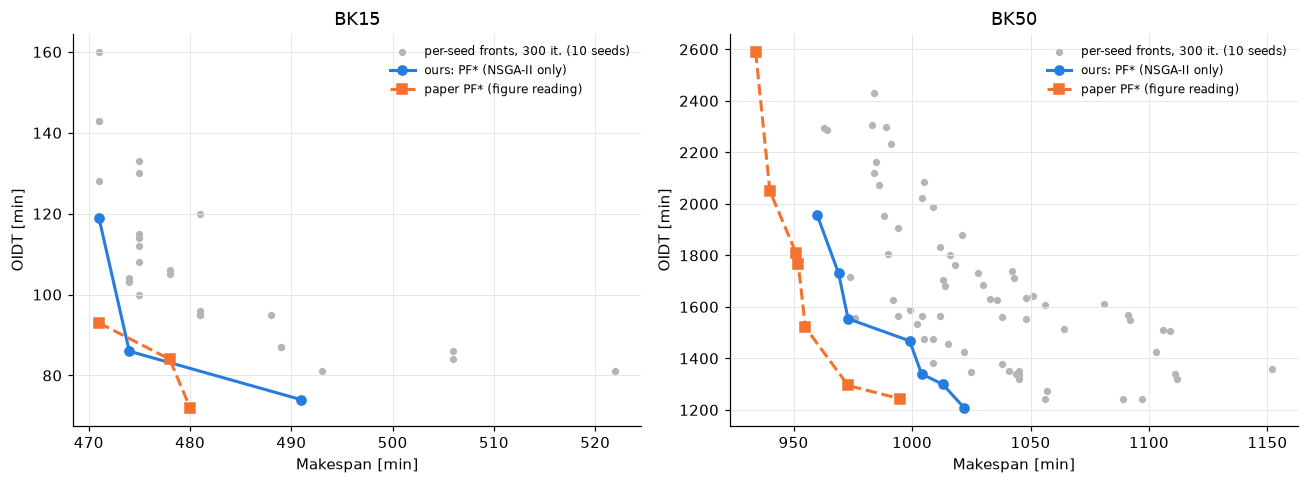

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (inst, v) in zip(axes, S['instances'].items()):
    sub = fronts[(fronts.instance == inst) & (fronts.iteration == 300)]
    ax.scatter(sub.makespan, sub.oidt, s=14, color='#b5b5b5', label='per-seed fronts, 300 it. (10 seeds)', zorder=1)
    st = np.array(v['pf_star'])
    ax.plot(st[:, 0], st[:, 1], '-o', color=OURS, ms=6, label='ours: PF* (NSGA-II only)', zorder=3)
    pp = np.array(PAPER[inst]['pf_star'])
    ax.plot(pp[:, 0], pp[:, 1], '--s', color=PAPERC, ms=6, label='paper PF* (figure reading)', zorder=3)
    ax.set_title(inst); ax.set_xlabel('Makespan [min]'); ax.set_ylabel('OIDT [min]')
    ax.legend(fontsize=8, frameon=False)
plt.tight_layout()

## 3. Candidate fronts per iteration: seed 1 (paper protocol) vs. paper Fig. 10a (BK50) / Fig. 9 (BK15)

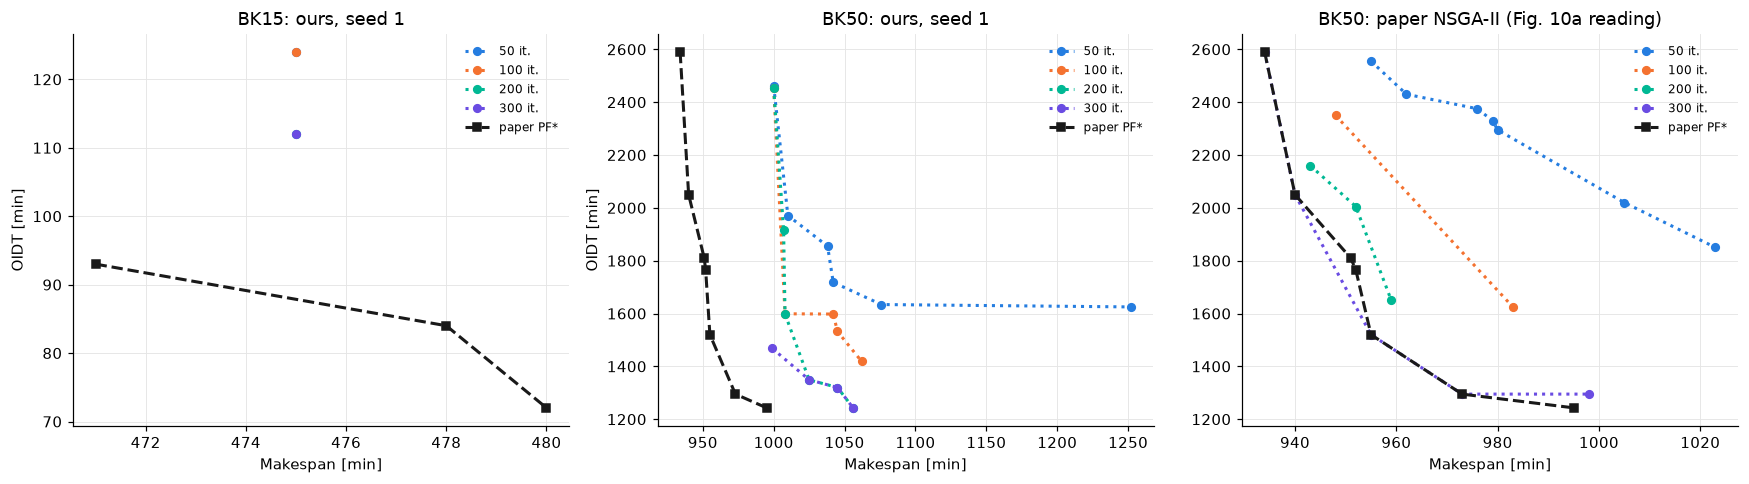

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, inst in zip(axes[:2], ['BK15', 'BK50']):
    for it, col in ITER_COLORS.items():
        g = fronts[(fronts.instance == inst) & (fronts.seed == 1) & (fronts.iteration == it)].sort_values('makespan')
        ax.plot(g.makespan, g.oidt, ':o', color=col, ms=5, label=f'{it} it.')
    pp = np.array(PAPER[inst]['pf_star'])
    ax.plot(pp[:, 0], pp[:, 1], '--s', color='#191919', ms=5, label='paper PF*')
    ax.set_title(f'{inst}: ours, seed 1'); ax.set_xlabel('Makespan [min]'); ax.set_ylabel('OIDT [min]')
    ax.legend(fontsize=8, frameon=False)
ax = axes[2]
for it, col in ITER_COLORS.items():
    f = np.array(PAPER['BK50']['nsga2_fronts'][it])
    ax.plot(f[:, 0], f[:, 1], ':o', color=col, ms=5, label=f'{it} it.')
pp = np.array(PAPER['BK50']['pf_star'])
ax.plot(pp[:, 0], pp[:, 1], '--s', color='#191919', ms=5, label='paper PF*')
ax.set_title('BK50: paper NSGA-II (Fig. 10a reading)'); ax.set_xlabel('Makespan [min]')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()

In [9]:
s1 = metrics[metrics.seed == 1].set_index(['instance', 'iteration'])
s1[['front_size', 'min_makespan', 'min_oidt']]

front_size  min_makespan  min_oidt
instance iteration                                    
BK15     50                  1         475.0     124.0
         100                 1         475.0     124.0
         200                 1         475.0     112.0
         300                 1         475.0     112.0
BK50     50                  6        1000.0    1625.0
         100                 5        1000.0    1419.0
         200                 6        1000.0    1243.0
         300                 4         999.0    1243.0

## 4. Indicators vs. iteration (paper Table 4, Fig. 11, Fig. 12)

PDS (Eq. 2, lower better), MSF (Eq. 3 as printed, higher better), DPF (Eq. 4, raw minutes; the paper's Fig. 11 axis is in minutes),
RHA (Eq. 6, %; objectives scaled to [0, 1] over all NSGA-II fronts, RV = (1.1, 1.1)).
`seed1` follows the paper protocol; `median [IQR]` summarises the 10 seeds.

In [10]:
pkey = {'PDS': 'nsga2_pds', 'MSF': 'nsga2_msf', 'DPF_raw': 'nsga2_dpf', 'RHA': 'nsga2_rha'}
rows = []
for (inst, it), g in metrics.groupby(['instance', 'iteration']):
    r = {'instance': inst, 'iteration': it}
    for m, pk in pkey.items():
        q1, q2, q3 = g[m].quantile([.25, .5, .75])
        r[(m, 'paper')] = PAPER[inst][pk][it]
        r[(m, 'seed1')] = round(float(g[g.seed == 1][m].iloc[0]), 2)
        r[(m, 'median [IQR]')] = f'{q2:.2f} [{q1:.2f}, {q3:.2f}]'
    rows.append(r)
tab = pd.DataFrame(rows).set_index(['instance', 'iteration'])
tab.columns = pd.MultiIndex.from_tuples(tab.columns)
tab

PDS                            MSF        \
                   paper seed1       median [IQR] paper seed1   
instance iteration                                              
BK15     50         0.33  0.33  0.33 [0.33, 0.33]  1.13  0.00   
         100        0.33  0.33  0.33 [0.33, 0.33]  1.84  0.00   
         200        0.20  0.33  0.33 [0.20, 0.33]  0.17  0.00   
         300        0.00  0.33  0.33 [0.17, 0.33]  0.80  0.00   
BK50     50         0.10  0.14  0.14 [0.14, 0.14]  0.82  0.29   
         100        0.14  0.14  0.14 [0.14, 0.14]  1.00  0.44   
         200        0.05  0.14  0.14 [0.14, 0.14]  1.00  0.50   
         300       -0.09  0.07  0.14 [0.07, 0.14]  0.98  0.76   

                                      DPF_raw          \
                         median [IQR]   paper   seed1   
instance iteration                                      
BK15     50         0.69 [0.40, 0.77]      44   32.30   
         100        0.74 [0.60, 0.79]      41   32.30   
         200        0.79 [0.73, 0.84]      32   25.10   
         300        0.79 [0.76, 0.87]      11   25.10   
BK50     50         0.29 [0.20, 0.46]     258  216.08   
         100        0.35 [0.29, 0.48]     242  153.59   
         200        0.57 [0.45, 0.71]     235   69.71   
         300        0.61 [0.54, 0.73]      78  136.15   

                                              RHA                               
                               median [IQR] paper  seed1          median [IQR]  
instance iteration                                                              
BK15     50            22.25 [17.14, 25.12]  67.0  59.27  74.31 [71.84, 79.11]  
         100           18.99 [14.69, 21.94]  71.0  59.27  80.51 [74.63, 83.18]  
         200           14.08 [11.35, 19.99]  82.0  68.70  83.97 [78.87, 87.88]  
         300            13.05 [9.94, 19.99]  97.0  68.70  84.01 [80.08, 90.27]  
BK50     50         282.81 [192.26, 294.52]  66.0  70.96  64.54 [62.10, 70.06]  
         100        148.75 [126.56, 179.59]  78.5  80.46  75.91 [70.30, 80.09]  
         200          93.16 [70.42, 128.54]  79.5  87.67  83.26 [78.02, 86.68]  
         300          90.72 [74.57, 125.04]  97.5  89.14  88.47 [83.78, 92.21]

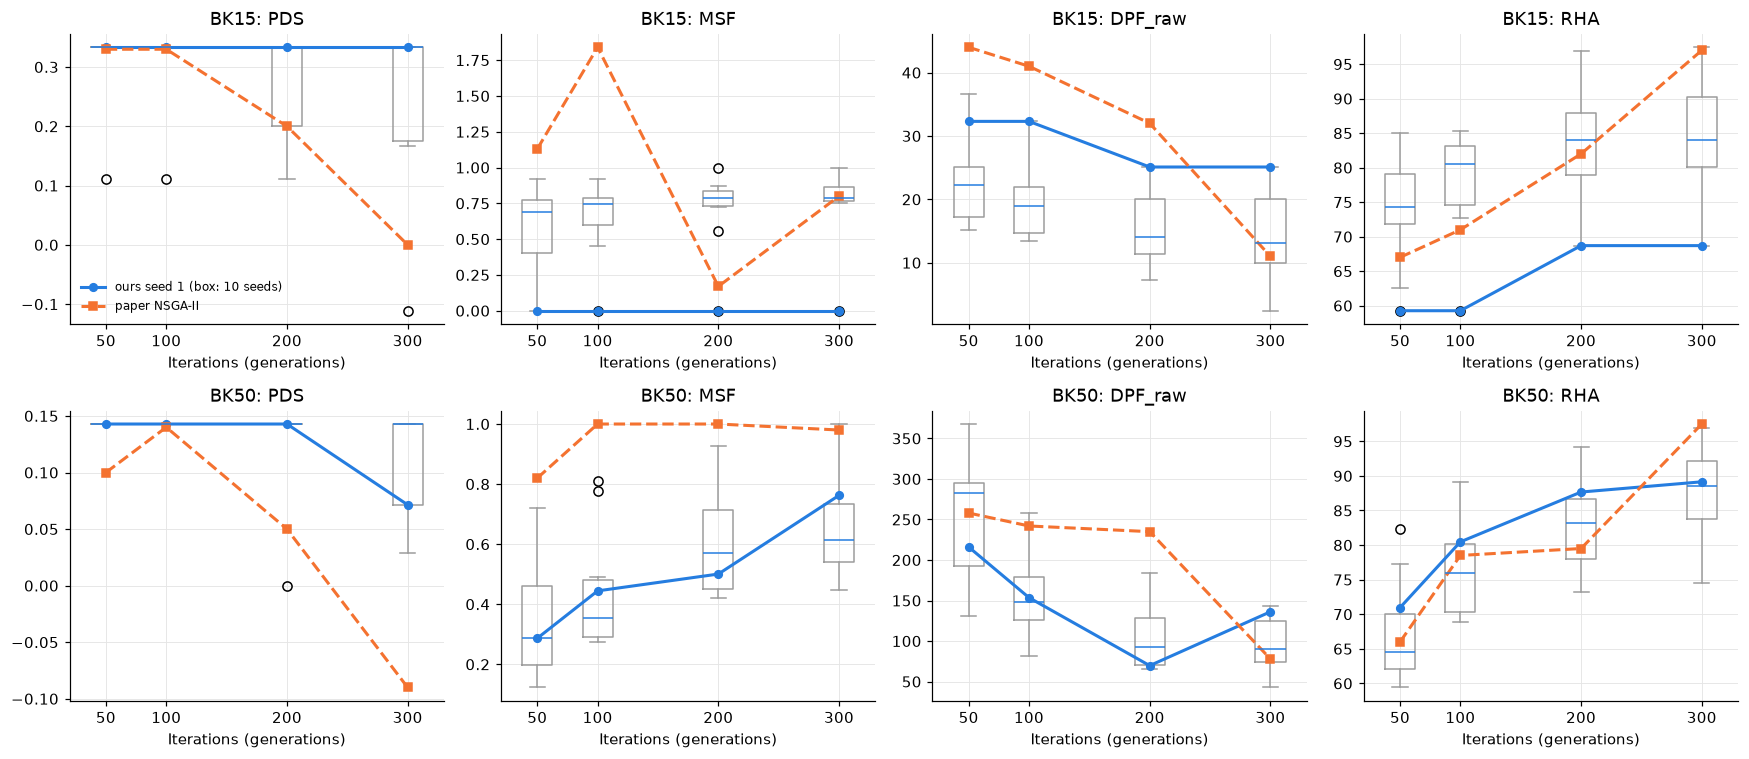

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
its = cfg['iterations']
for i, inst in enumerate(['BK15', 'BK50']):
    for j, (m, pk) in enumerate(pkey.items()):
        ax = axes[i, j]
        g = metrics[metrics.instance == inst]
        data = [g[g.iteration == it][m].values for it in its]
        ax.boxplot(data, positions=its, widths=25, showfliers=True,
                   medianprops={'color': OURS}, boxprops={'color': '#9c9c9c'},
                   whiskerprops={'color': '#9c9c9c'}, capprops={'color': '#9c9c9c'})
        ax.plot(its, [g[(g.iteration == it) & (g.seed == 1)][m].iloc[0] for it in its], '-o', color=OURS, ms=5,
                label='ours seed 1 (box: 10 seeds)')
        ax.plot(its, [PAPER[inst][pk][it] for it in its], '--s', color=PAPERC, ms=5, label='paper NSGA-II')
        ax.set_xticks(its); ax.set_xlim(20, 330)
        ax.set_title(f'{inst}: {m}'); ax.set_xlabel('Iterations (generations)')
        if i == 0 and j == 0:
            ax.legend(fontsize=8, frameon=False)
plt.tight_layout()

## 5. Convergence trace (population min makespan / min OIDT per generation)

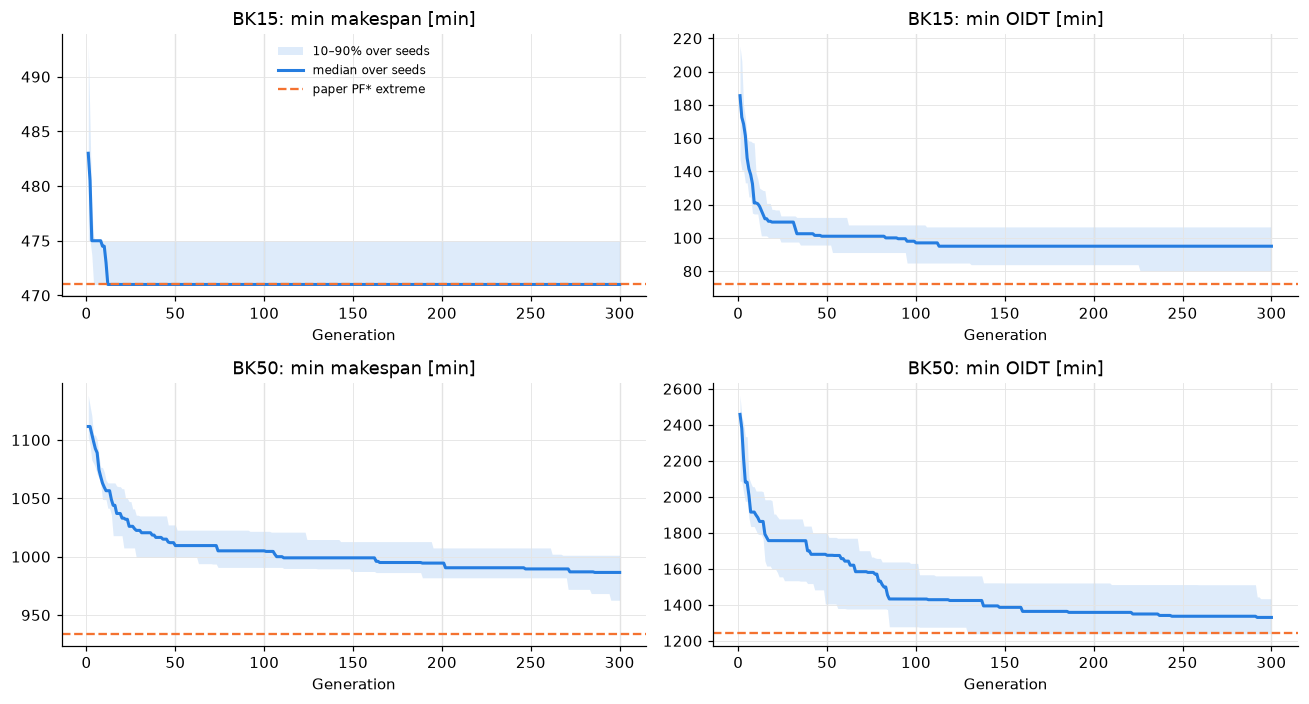

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))
for i, inst in enumerate(['BK15', 'BK50']):
    t = trace[trace.instance == inst]
    for j, (col, lab) in enumerate([('min_makespan', 'min makespan [min]'), ('min_oidt', 'min OIDT [min]')]):
        ax = axes[i, j]
        q = t.groupby('generation')[col].quantile([.1, .5, .9]).unstack()
        ax.fill_between(q.index, q[0.1], q[0.9], color=OURS, alpha=0.15, lw=0, label='10–90% over seeds')
        ax.plot(q.index, q[0.5], color=OURS, label='median over seeds')
        pp = np.array(PAPER[inst]['pf_star'])
        ref = pp[:, 0].min() if col == 'min_makespan' else pp[:, 1].min()
        ax.axhline(ref, color=PAPERC, ls='--', lw=1.5, label='paper PF* extreme')
        for it in cfg['iterations']:
            ax.axvline(it, color='#d0d0d0', lw=0.8, zorder=0)
        ax.set_title(f'{inst}: {lab}'); ax.set_xlabel('Generation')
        if j == 0 and i == 0:
            ax.legend(fontsize=8, frameon=False)
plt.tight_layout()

## 6. OIDT definition: union (objective) vs. paper M2 on the stored fronts

In [13]:
f300 = fronts[fronts.iteration == 300]
f300.groupby('instance').agg(n=('oidt', 'size'), oidt_union_min=('oidt', 'min'), oidt_m2_min=('oidt_m2', 'min'),
                             mean_gap_union_minus_m2=('oidt', lambda s: (s - f300.loc[s.index, 'oidt_m2']).mean()))

,n,oidt_union_min,oidt_m2_min,mean_gap_union_minus_m2
instance,,,,
BK15,31,74,-12,85.516129
BK50,73,1208,149,1037.219178


## 7. Observations vs. the paper (results of 2026-11-27, git state in `summary.json` meta)

- **Settings / feasibility.** Table 5 settings, 15,000 evaluations per run. Infeasible rate 0.022% (BK15) and 0% (BK50);
  every stored front solution passes `verify_schedule`.
- **BK15.** Min makespan 471 is reached in 7/10 seeds (= paper E1 makespan, = CP-SAT optimum). The paper's PF*
  (471, 93) – (478, 84) – (480, 72) dominates 2 of our 3 PF* points; only (474, 86) is not dominated. Our best OIDT near
  E2 is 74 at makespan 491 (paper 72 at 480). Seed 1 (paper protocol) ends with a single point (475, 112).
- **BK50.** Our PF* spans makespan 960–1022 and OIDT 1956–1208; the paper's spans 934–995 and 2590–1243
  (E1 ≈ 934 from Fig. 10a, consistent with E2 = E1 + 61 = 995). 6 of 7 of our points are dominated by the paper's PF*;
  (1022, 1208) is the only exception and has *lower* OIDT than the paper's E2 (1243). Seed medians at 300 it.:
  makespan 986.5, OIDT 1330. The low-makespan end (< 960) is not reached; the E1→E2 OIDT drop is 748 vs. 1348 in the paper.
- **Trends.** RHA rises and DPF falls with iterations, as in the paper's Fig. 11/12 for NSGA-II. BK50 DPF (raw minutes)
  is on the paper's scale (median 283 → 91 vs. paper 258 → 78). Per-seed variability is large, so the paper's single-run
  values sit inside our seed spread for most points (RHA BK50, DPF BK15/BK50).
- **Table 4.** PDS is mostly 0.33 (BK15) / 0.14 (BK50) because a single run rarely contributes to the pooled PF*; the
  paper's NSGA-II reaches 0.00 / −0.09 at 300 it. because its PF* is largely made of NSGA-II's 300-iteration front.
  MSF as printed gives 0 for a single-point front (seed 1 on BK15).
- **Time.** 50 iterations take ~4 s (BK15) and ~54 s (BK50) per run vs. 13 min / 342 min in the paper (p.14);
  hardware and implementation differ, so only relative comparisons are meaningful.